# Facility pooling vs Stovepipe — PRIM on delta (2 ambulances)


In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ema_workbench.analysis import prim

RESULTS_PATH = _root / "data_cluster/resource_grid/results.csv"
df = pd.read_csv(RESULTS_PATH)
df = df[df["n_amb_r1_to_ccp"] == 2]
print(f"Loaded {len(df)} runs (2 ambulances)")

UNCERTAINTIES = ["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min", "bcas_rate"]
LEVERS = UNCERTAINTIES
MATCH_COLS = ["seed", "ccp_r1_same_bn_min", "ccp_r1_inter_bn_min", "bcas_rate"]

def get_policy(df_sub, fac, amb):
    return df_sub[(df_sub["facility_eligibility"] == fac) & (df_sub["ambulance_eligibility"] == amb)]

OUTCOME_COLS = [c for c in df.columns if c.startswith(("death_rate", "mortality_", "median_wait", "frac_", "n_patients"))]
policy_raw = get_policy(df, 1, 0)
stove_raw  = get_policy(df, 0, 0)

policy = policy_raw.groupby(LEVERS)[OUTCOME_COLS].mean().reset_index()
stove  = stove_raw.groupby(LEVERS)[OUTCOME_COLS].mean().reset_index()
policy = policy.sort_values(LEVERS).reset_index(drop=True)
stove  = stove.sort_values(LEVERS).reset_index(drop=True)

assert len(policy) == len(stove), f"Mismatch: {len(policy)} vs {len(stove)}"
assert (policy[LEVERS].values == stove[LEVERS].values).all()

delta = policy["death_rate_T1_BCAS"].values - stove["death_rate_T1_BCAS"].values
print(f"{len(policy)} scenarios")
print(f"Delta: min={delta.min():.4f}, median={np.median(delta):.4f}, mean={delta.mean():.4f}, max={delta.max():.4f}")
print(f"Helps: {(delta < 0).sum()}, Indifferent: {(delta == 0).sum()}, Hurts: {(delta > 0).sum()}")

x = policy[UNCERTAINTIES].astype(float)

def show_tradeoff_highlighted(box, step=None):
    fig = box.show_tradeoff()
    if step is not None:
        traj = box.peeling_trajectory
        if step in traj.index:
            row = traj.loc[step]
            ax = fig.axes[0]
            ax.plot(row["coverage"], row["density"], "o", color="red", markersize=14, zorder=5,
                    markerfacecolor="none", markeredgecolor="red", markeredgewidth=2.5)
    plt.show()


C:\Users\User\Documents\thesis\medevac_model\.venv\Lib\site-packages\ema_workbench\em_framework\__init__.py:101: UserWarning: ipyparallel not installed - IpyparalleEvaluator not available
  warnings.warn("ipyparallel not installed - IpyparalleEvaluator not available")


Loaded 405600 runs (2 ambulances)
1014 scenarios
Delta: min=-0.4333, median=0.0000, mean=-0.0115, max=0.0306
Helps: 402, Indifferent: 239, Hurts: 373


## Delta distribution


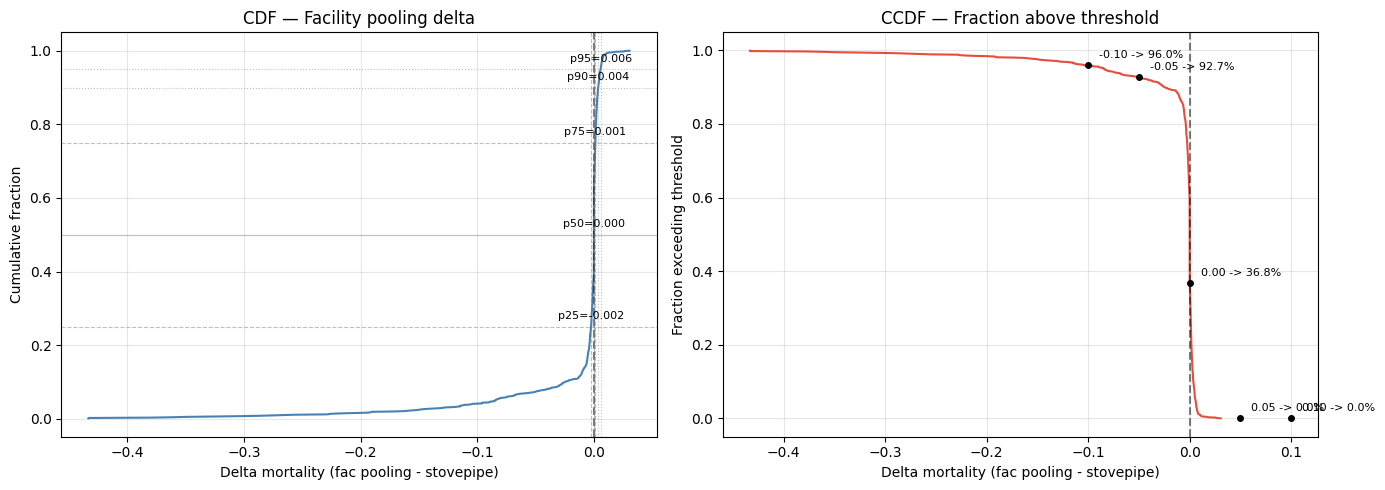

In [2]:
sorted_d = np.sort(delta)
cdf = np.arange(1, len(sorted_d) + 1) / len(sorted_d)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(sorted_d, cdf, color="steelblue", linewidth=1.5)
axes[0].axvline(0, color="black", linestyle="--", alpha=0.5)
axes[0].set_xlabel("Delta mortality (fac pooling - stovepipe)")
axes[0].set_ylabel("Cumulative fraction")
axes[0].set_title("CDF — Facility pooling delta")
axes[0].grid(True, alpha=0.3)

for p, ls in [(0.25, "--"), (0.50, "-"), (0.75, "--"), (0.90, ":"), (0.95, ":")]:
    val = np.percentile(delta, p * 100)
    axes[0].axhline(p, color="grey", linestyle=ls, alpha=0.5, linewidth=0.8)
    axes[0].axvline(val, color="grey", linestyle=ls, alpha=0.5, linewidth=0.8)
    axes[0].text(val, p + 0.02, f"p{int(p*100)}={val:.3f}", fontsize=8, ha="center")

axes[1].plot(sorted_d, 1 - cdf, color="#e74c3c", linewidth=1.5)
axes[1].axvline(0, color="black", linestyle="--", alpha=0.5)
axes[1].set_xlabel("Delta mortality (fac pooling - stovepipe)")
axes[1].set_ylabel("Fraction exceeding threshold")
axes[1].set_title("CCDF — Fraction above threshold")
axes[1].grid(True, alpha=0.3)

for t in [-0.10, -0.05, 0.0, 0.05, 0.10]:
    frac = (delta > t).mean()
    axes[1].plot(t, frac, "o", color="black", markersize=4)
    axes[1].annotate(f"{t:.2f} -> {frac:.1%}", (t, frac), textcoords="offset points",
                     xytext=(8, 5), fontsize=8)

plt.tight_layout()
plt.show()


## PRIM — Pooling helps


Target scenarios: 74 / 1014 (7.3%)


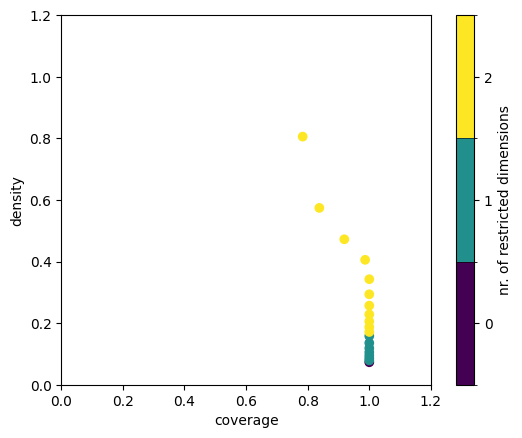

In [52]:
# === Pooling helps: delta < 0 ===
y = delta < -0.05

print(f"Target scenarios: {y.sum()} / {len(y)} ({y.mean():.1%})")
p_box1 = prim.Prim(x, y, threshold=0.2)
box1 = p_box1.find_box()
box1.show_tradeoff()
plt.show()


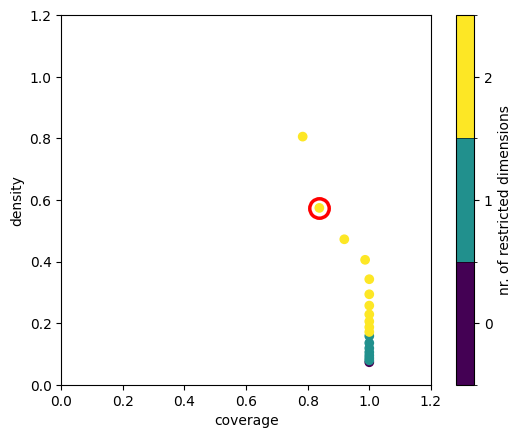

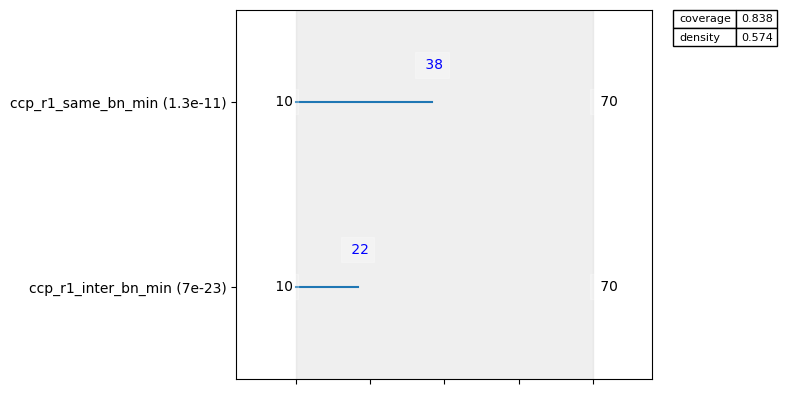

In [54]:
STEP_1 = 17  # e.g. 10, 15, 20

if STEP_1 is not None:
    box1.select(STEP_1)
show_tradeoff_highlighted(box1, step=STEP_1)

box1.inspect(style="graph")
plt.show()


In [55]:
box1.inspect()


coverage      0.837838
density       0.574074
id           17.000000
k            62.000000
mass          0.106509
mean          0.574074
n           108.000000
res_dim       2.000000
Name: 17, dtype: float64

                    box 17                             
                       min   max qp value      qp value
ccp_r1_inter_bn_min   10.0  22.5      NaN  7.013458e-23
ccp_r1_same_bn_min    10.0  37.5      NaN  1.263578e-11


[None]

C:\Users\User\AppData\Local\Temp\ipykernel_18400\3306705430.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([_in, _out], labels=["Inside box", "Outside box"], patch_artist=True, showfliers=False,


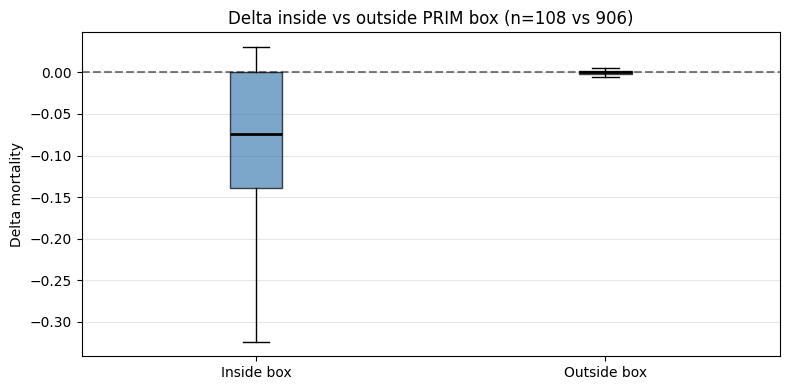

Inside:  n=108, helps=74.1%, hurts=10.2%, median=-0.0742, 95% CI [-0.0857, -0.0449]
Outside: n=906, helps=35.5%, hurts=40.0%, median=+0.0000


In [56]:
from scipy.stats import bootstrap as _bootstrap
_in = delta[box1.yi]
_out = np.delete(delta, box1.yi)

fig, ax = plt.subplots(figsize=(8, 4))
bp = ax.boxplot([_in, _out], labels=["Inside box", "Outside box"], patch_artist=True, showfliers=False,
                medianprops=dict(color="black", linewidth=2))
bp["boxes"][0].set_facecolor("steelblue"); bp["boxes"][0].set_alpha(0.7)
bp["boxes"][1].set_facecolor("#999999"); bp["boxes"][1].set_alpha(0.7)
ax.axhline(0, color="black", linestyle="--", alpha=0.5)
ax.set_ylabel("Delta mortality")
ax.grid(True, alpha=0.3, axis="y")
plt.title(f"Delta inside vs outside PRIM box (n={len(_in)} vs {len(_out)})")
plt.tight_layout()
plt.show()

_ci_in = _bootstrap((_in,), np.median, confidence_level=0.95, n_resamples=9999, method='percentile').confidence_interval
print(f"Inside:  n={len(_in)}, helps={(_in<0).mean():.1%}, hurts={(_in>0).mean():.1%}, median={np.median(_in):+.4f}, 95% CI [{_ci_in.low:+.4f}, {_ci_in.high:+.4f}]")
print(f"Outside: n={len(_out)}, helps={(_out<0).mean():.1%}, hurts={(_out>0).mean():.1%}, median={np.median(_out):+.4f}")


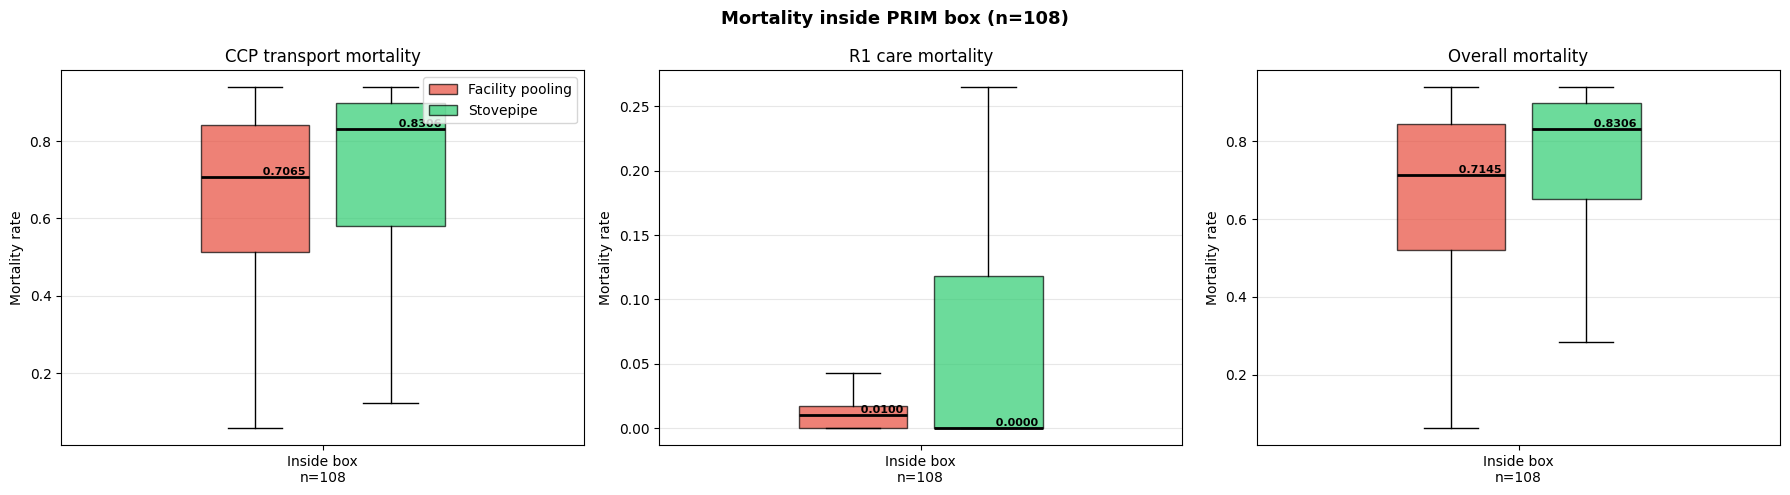

  mortality_ccp_transport_T1: Facility pooling=100.0%, Stovepipe=100.0%
  mortality_r1_care_T1: Facility pooling=74.1%, Stovepipe=38.9%

Median mortality with 95% CI inside PRIM box (n=108):
  mortality_ccp_transport_T1: Facility pooling median=0.7065 CI=[0.6444, 0.7530]
  mortality_ccp_transport_T1: Stovepipe median=0.8306 CI=[0.7322, 0.8788]
  mortality_r1_care_T1: Facility pooling median=0.0100 CI=[0.0063, 0.0113]
  mortality_r1_care_T1: Stovepipe median=0.0000 CI=[0.0000, 0.0000]
  death_rate_T1_BCAS: Facility pooling median=0.7145 CI=[0.6509, 0.7582]
  death_rate_T1_BCAS: Stovepipe median=0.8306 CI=[0.7322, 0.8788]


In [57]:
_idx = box1.yi
_l1, _l2 = "Facility pooling", "Stovepipe"
_df1, _df2 = policy, stove

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
_c1, _c2 = "#e74c3c", "#2ecc71"
_w = 0.35

for _ai, (_col, _title) in enumerate([
    ("mortality_ccp_transport_T1", "CCP transport mortality"),
    ("mortality_r1_care_T1", "R1 care mortality"),
    ("death_rate_T1_BCAS", "Overall mortality"),
]):
    _d1 = _df1[_col].values[_idx]
    _d2 = _df2[_col].values[_idx]
    _bp1 = axes[_ai].boxplot([_d1], positions=[-_w/2], widths=_w*0.8, patch_artist=True,
                              showfliers=False, medianprops=dict(color="black", linewidth=2))
    _bp2 = axes[_ai].boxplot([_d2], positions=[_w/2], widths=_w*0.8, patch_artist=True,
                              showfliers=False, medianprops=dict(color="black", linewidth=2))
    _bp1["boxes"][0].set_facecolor(_c1); _bp1["boxes"][0].set_alpha(0.7)
    _bp2["boxes"][0].set_facecolor(_c2); _bp2["boxes"][0].set_alpha(0.7)
    axes[_ai].set_xticks([0])
    axes[_ai].set_xticklabels([f"Inside box\nn={len(_idx)}"])
    axes[_ai].set_title(_title)
    axes[_ai].set_ylabel("Mortality rate")
    axes[_ai].grid(True, alpha=0.3, axis="y")
    for _bp, _xp in [(_bp1, -_w/2), (_bp2, _w/2)]:
        _med = _bp["medians"][0].get_ydata()[0]
        axes[_ai].text(_xp, _med, f"  {_med:.4f}", ha="left", fontsize=8, fontweight="bold", va="bottom")

axes[0].legend([_bp1["boxes"][0], _bp2["boxes"][0]], [_l1, _l2], loc="upper right")
plt.suptitle(f"Mortality inside PRIM box (n={len(_idx)})", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

for _col in ["mortality_ccp_transport_T1", "mortality_r1_care_T1"]:
    _f1 = (_df1[_col].values[_idx] > 0).mean()
    _f2 = (_df2[_col].values[_idx] > 0).mean()
    print(f"  {_col}: {_l1}={_f1:.1%}, {_l2}={_f2:.1%}")

from scipy.stats import bootstrap as _bootstrap
print(f"\nMedian mortality with 95% CI inside PRIM box (n={len(_idx)}):")
for _col in ["mortality_ccp_transport_T1", "mortality_r1_care_T1", "death_rate_T1_BCAS"]:
    _vals = _df1[_col].values[_idx]
    if len(set(_vals)) > 1:
        _ci = _bootstrap((_vals,), np.median, confidence_level=0.95, n_resamples=9999, method='percentile').confidence_interval
        print(f"  {_col}: {_l1} median={np.median(_vals):.4f} CI=[{_ci.low:.4f}, {_ci.high:.4f}]")
    else:
        print(f"  {_col}: {_l1} median={np.median(_vals):.4f} (constant)")
    _vals2 = _df2[_col].values[_idx]
    if len(set(_vals2)) > 1:
        _ci2 = _bootstrap((_vals2,), np.median, confidence_level=0.95, n_resamples=9999, method='percentile').confidence_interval
        print(f"  {_col}: {_l2} median={np.median(_vals2):.4f} CI=[{_ci2.low:.4f}, {_ci2.high:.4f}]")
    else:
        print(f"  {_col}: {_l2} median={np.median(_vals2):.4f} (constant)")


## PRIM — Indifferent


Target scenarios: 239 / 1014 (23.6%)


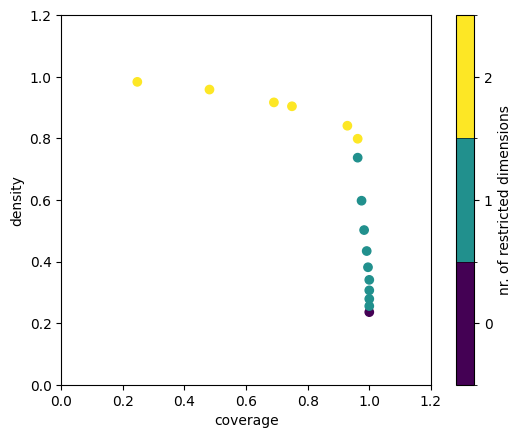

In [58]:
# === Indifferent: delta == 0.00 ===
y = delta == 0.00

print(f"Target scenarios: {y.sum()} / {len(y)} ({y.mean():.1%})")
p_box2 = prim.Prim(x, y, threshold=0.5)
box2 = p_box2.find_box()
box2.show_tradeoff()
plt.show()


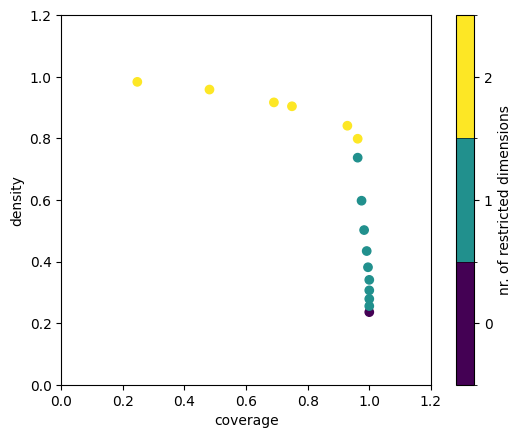

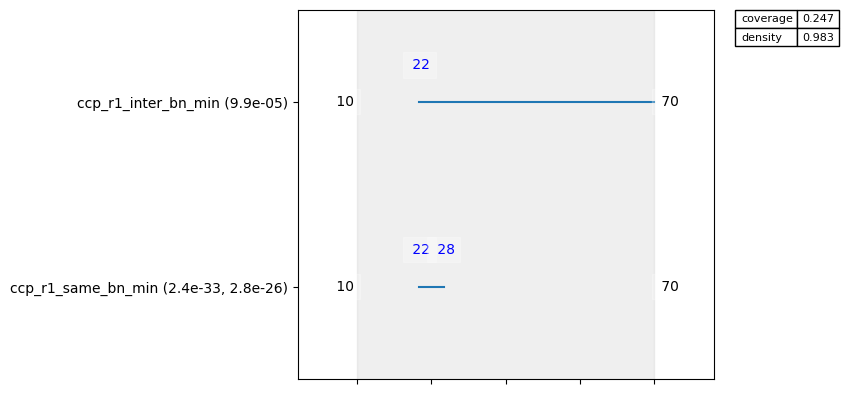

In [59]:
STEP_2 = None   # e.g. 10, 15, 20

if STEP_2 is not None:
    box2.select(STEP_2)
show_tradeoff_highlighted(box2, step=STEP_2)

box2.inspect(style="graph")
plt.show()


In [60]:
box2.inspect()


coverage     0.246862
density      0.983333
id          15.000000
k           59.000000
mass         0.059172
mean         0.983333
n           60.000000
res_dim      2.000000
Name: 15, dtype: float64

                    box 15                                  
                       min   max      qp value      qp value
ccp_r1_same_bn_min    22.5  27.5  2.382929e-33  2.830889e-26
ccp_r1_inter_bn_min   22.5  70.0  9.888052e-05           NaN


[None]

C:\Users\User\AppData\Local\Temp\ipykernel_18400\1114736765.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([_in, _out], labels=["Inside box", "Outside box"], patch_artist=True, showfliers=False,


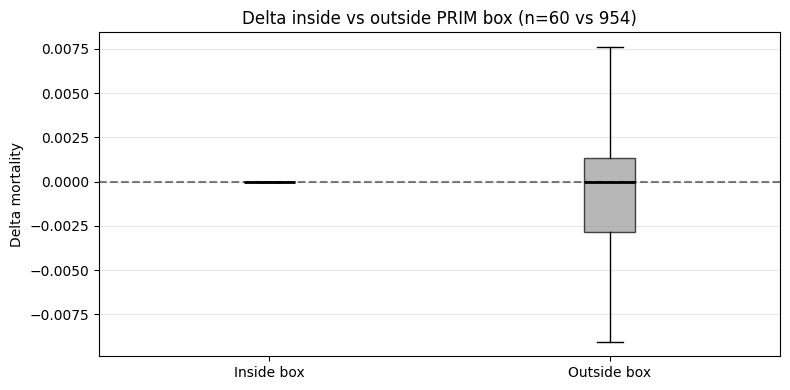

Inside:  n=60, helps=0.0%, hurts=1.7%, median=+0.0000, 95% CI [+0.0000, +0.0000]
Outside: n=954, helps=42.1%, hurts=39.0%, median=+0.0000


In [61]:
from scipy.stats import bootstrap as _bootstrap
_in = delta[box2.yi]
_out = np.delete(delta, box2.yi)

fig, ax = plt.subplots(figsize=(8, 4))
bp = ax.boxplot([_in, _out], labels=["Inside box", "Outside box"], patch_artist=True, showfliers=False,
                medianprops=dict(color="black", linewidth=2))
bp["boxes"][0].set_facecolor("steelblue"); bp["boxes"][0].set_alpha(0.7)
bp["boxes"][1].set_facecolor("#999999"); bp["boxes"][1].set_alpha(0.7)
ax.axhline(0, color="black", linestyle="--", alpha=0.5)
ax.set_ylabel("Delta mortality")
ax.grid(True, alpha=0.3, axis="y")
plt.title(f"Delta inside vs outside PRIM box (n={len(_in)} vs {len(_out)})")
plt.tight_layout()
plt.show()

_ci_in = _bootstrap((_in,), np.median, confidence_level=0.95, n_resamples=9999, method='percentile').confidence_interval
print(f"Inside:  n={len(_in)}, helps={(_in<0).mean():.1%}, hurts={(_in>0).mean():.1%}, median={np.median(_in):+.4f}, 95% CI [{_ci_in.low:+.4f}, {_ci_in.high:+.4f}]")
print(f"Outside: n={len(_out)}, helps={(_out<0).mean():.1%}, hurts={(_out>0).mean():.1%}, median={np.median(_out):+.4f}")


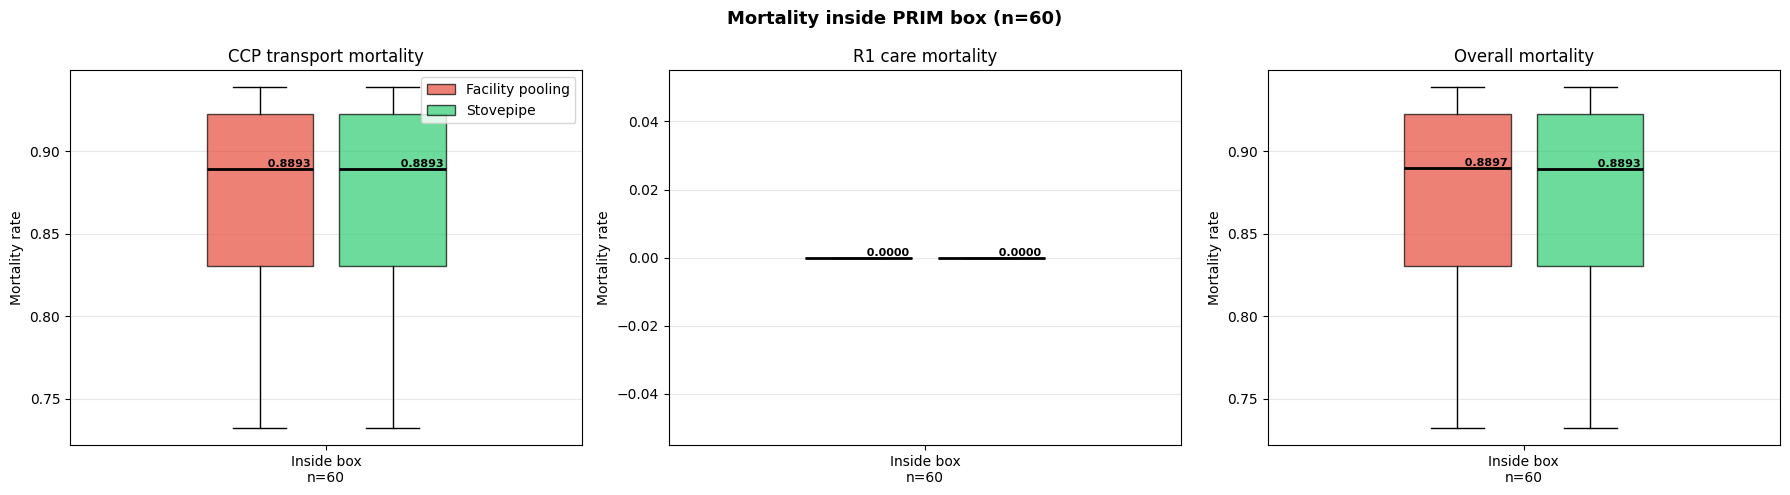

  mortality_ccp_transport_T1: Facility pooling=100.0%, Stovepipe=100.0%
  mortality_r1_care_T1: Facility pooling=1.7%, Stovepipe=0.0%

Median mortality with 95% CI inside PRIM box (n=60):
  mortality_ccp_transport_T1: Facility pooling median=0.8893 CI=[0.8788, 0.8997]
  mortality_ccp_transport_T1: Stovepipe median=0.8893 CI=[0.8788, 0.8997]
  mortality_r1_care_T1: Facility pooling median=0.0000 CI=[0.0000, 0.0000]
  mortality_r1_care_T1: Stovepipe median=0.0000 (constant)
  death_rate_T1_BCAS: Facility pooling median=0.8897 CI=[0.8788, 0.8997]
  death_rate_T1_BCAS: Stovepipe median=0.8893 CI=[0.8788, 0.8997]


In [12]:
_idx = box2.yi
_l1, _l2 = "Facility pooling", "Stovepipe"
_df1, _df2 = policy, stove

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
_c1, _c2 = "#e74c3c", "#2ecc71"
_w = 0.35

for _ai, (_col, _title) in enumerate([
    ("mortality_ccp_transport_T1", "CCP transport mortality"),
    ("mortality_r1_care_T1", "R1 care mortality"),
    ("death_rate_T1_BCAS", "Overall mortality"),
]):
    _d1 = _df1[_col].values[_idx]
    _d2 = _df2[_col].values[_idx]
    _bp1 = axes[_ai].boxplot([_d1], positions=[-_w/2], widths=_w*0.8, patch_artist=True,
                              showfliers=False, medianprops=dict(color="black", linewidth=2))
    _bp2 = axes[_ai].boxplot([_d2], positions=[_w/2], widths=_w*0.8, patch_artist=True,
                              showfliers=False, medianprops=dict(color="black", linewidth=2))
    _bp1["boxes"][0].set_facecolor(_c1); _bp1["boxes"][0].set_alpha(0.7)
    _bp2["boxes"][0].set_facecolor(_c2); _bp2["boxes"][0].set_alpha(0.7)
    axes[_ai].set_xticks([0])
    axes[_ai].set_xticklabels([f"Inside box\nn={len(_idx)}"])
    axes[_ai].set_title(_title)
    axes[_ai].set_ylabel("Mortality rate")
    axes[_ai].grid(True, alpha=0.3, axis="y")
    for _bp, _xp in [(_bp1, -_w/2), (_bp2, _w/2)]:
        _med = _bp["medians"][0].get_ydata()[0]
        axes[_ai].text(_xp, _med, f"  {_med:.4f}", ha="left", fontsize=8, fontweight="bold", va="bottom")

axes[0].legend([_bp1["boxes"][0], _bp2["boxes"][0]], [_l1, _l2], loc="upper right")
plt.suptitle(f"Mortality inside PRIM box (n={len(_idx)})", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

for _col in ["mortality_ccp_transport_T1", "mortality_r1_care_T1"]:
    _f1 = (_df1[_col].values[_idx] > 0).mean()
    _f2 = (_df2[_col].values[_idx] > 0).mean()
    print(f"  {_col}: {_l1}={_f1:.1%}, {_l2}={_f2:.1%}")

from scipy.stats import bootstrap as _bootstrap
print(f"\nMedian mortality with 95% CI inside PRIM box (n={len(_idx)}):")
for _col in ["mortality_ccp_transport_T1", "mortality_r1_care_T1", "death_rate_T1_BCAS"]:
    _vals = _df1[_col].values[_idx]
    if len(set(_vals)) > 1:
        _ci = _bootstrap((_vals,), np.median, confidence_level=0.95, n_resamples=9999, method='percentile').confidence_interval
        print(f"  {_col}: {_l1} median={np.median(_vals):.4f} CI=[{_ci.low:.4f}, {_ci.high:.4f}]")
    else:
        print(f"  {_col}: {_l1} median={np.median(_vals):.4f} (constant)")
    _vals2 = _df2[_col].values[_idx]
    if len(set(_vals2)) > 1:
        _ci2 = _bootstrap((_vals2,), np.median, confidence_level=0.95, n_resamples=9999, method='percentile').confidence_interval
        print(f"  {_col}: {_l2} median={np.median(_vals2):.4f} CI=[{_ci2.low:.4f}, {_ci2.high:.4f}]")
    else:
        print(f"  {_col}: {_l2} median={np.median(_vals2):.4f} (constant)")


## PRIM — Pooling hurts


Target scenarios: 373 / 1014 (36.8%)


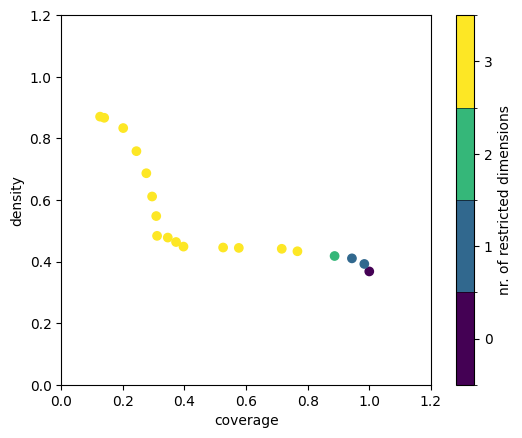

In [63]:
# === Pooling hurts: delta > 0 ===
y = delta > 0.00

print(f"Target scenarios: {y.sum()} / {len(y)} ({y.mean():.1%})")
p_box3 = prim.Prim(x, y, threshold=0.2)
box3 = p_box3.find_box()
box3.show_tradeoff()
plt.show()


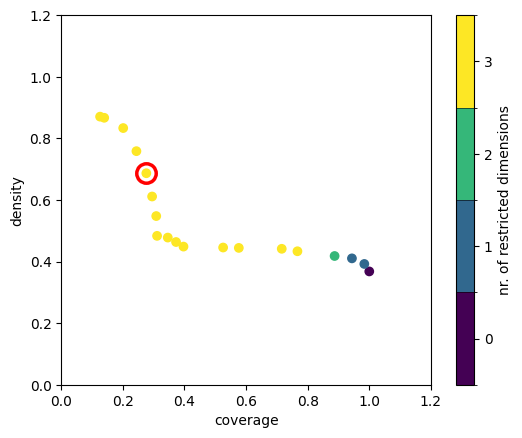

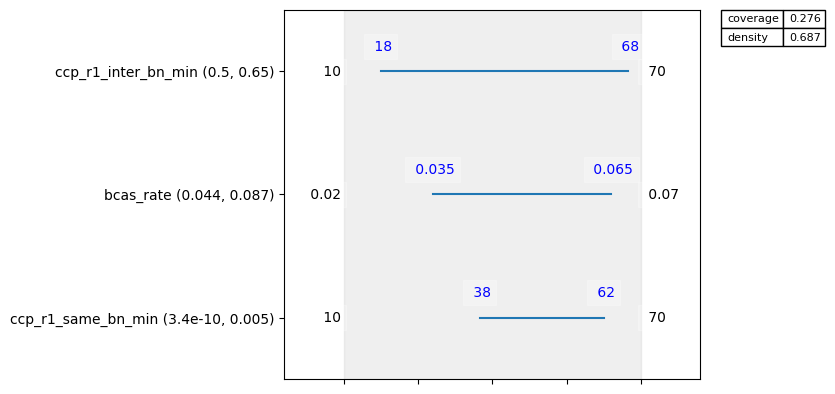

In [66]:
STEP_3 = 14  # e.g. 10, 15, 20

if STEP_3 is not None:
    box3.select(STEP_3)
show_tradeoff_highlighted(box3, step=STEP_3)

box3.inspect(style="graph")
plt.show()


In [67]:
box3.inspect()


coverage      0.276139
density       0.686667
id           14.000000
k           103.000000
mass          0.147929
mean          0.686667
n           150.000000
res_dim       3.000000
Name: 14, dtype: float64

                     box 14                                
                        min     max      qp value  qp value
ccp_r1_same_bn_min   37.500  62.500  3.374383e-10  0.005012
bcas_rate             0.035   0.065  4.362109e-02  0.086925
ccp_r1_inter_bn_min  17.500  67.500  5.042940e-01  0.645561


[None]

C:\Users\User\AppData\Local\Temp\ipykernel_18400\3598805638.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([_in, _out], labels=["Inside box", "Outside box"], patch_artist=True, showfliers=False,


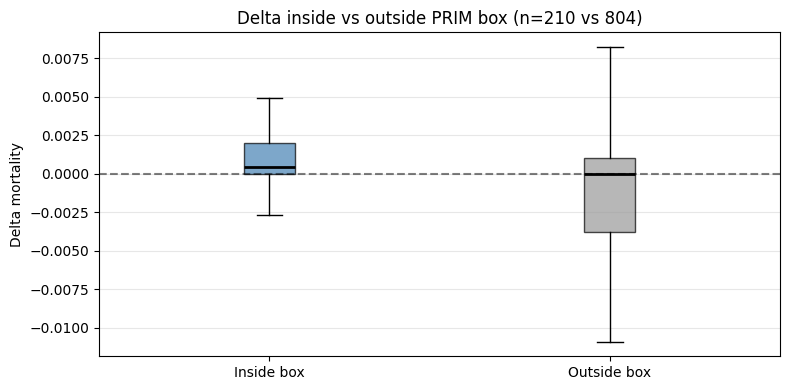

Inside:  n=210, helps=13.8%, hurts=54.8%, median=+0.0005, 95% CI [+0.0000, +0.0007]
Outside: n=804, helps=46.4%, hurts=32.1%, median=+0.0000


In [27]:
from scipy.stats import bootstrap as _bootstrap
_in = delta[box3.yi]
_out = np.delete(delta, box3.yi)

fig, ax = plt.subplots(figsize=(8, 4))
bp = ax.boxplot([_in, _out], labels=["Inside box", "Outside box"], patch_artist=True, showfliers=False,
                medianprops=dict(color="black", linewidth=2))
bp["boxes"][0].set_facecolor("steelblue"); bp["boxes"][0].set_alpha(0.7)
bp["boxes"][1].set_facecolor("#999999"); bp["boxes"][1].set_alpha(0.7)
ax.axhline(0, color="black", linestyle="--", alpha=0.5)
ax.set_ylabel("Delta mortality")
ax.grid(True, alpha=0.3, axis="y")
plt.title(f"Delta inside vs outside PRIM box (n={len(_in)} vs {len(_out)})")
plt.tight_layout()
plt.show()

_ci_in = _bootstrap((_in,), np.median, confidence_level=0.95, n_resamples=9999, method='percentile').confidence_interval
print(f"Inside:  n={len(_in)}, helps={(_in<0).mean():.1%}, hurts={(_in>0).mean():.1%}, median={np.median(_in):+.4f}, 95% CI [{_ci_in.low:+.4f}, {_ci_in.high:+.4f}]")
print(f"Outside: n={len(_out)}, helps={(_out<0).mean():.1%}, hurts={(_out>0).mean():.1%}, median={np.median(_out):+.4f}")


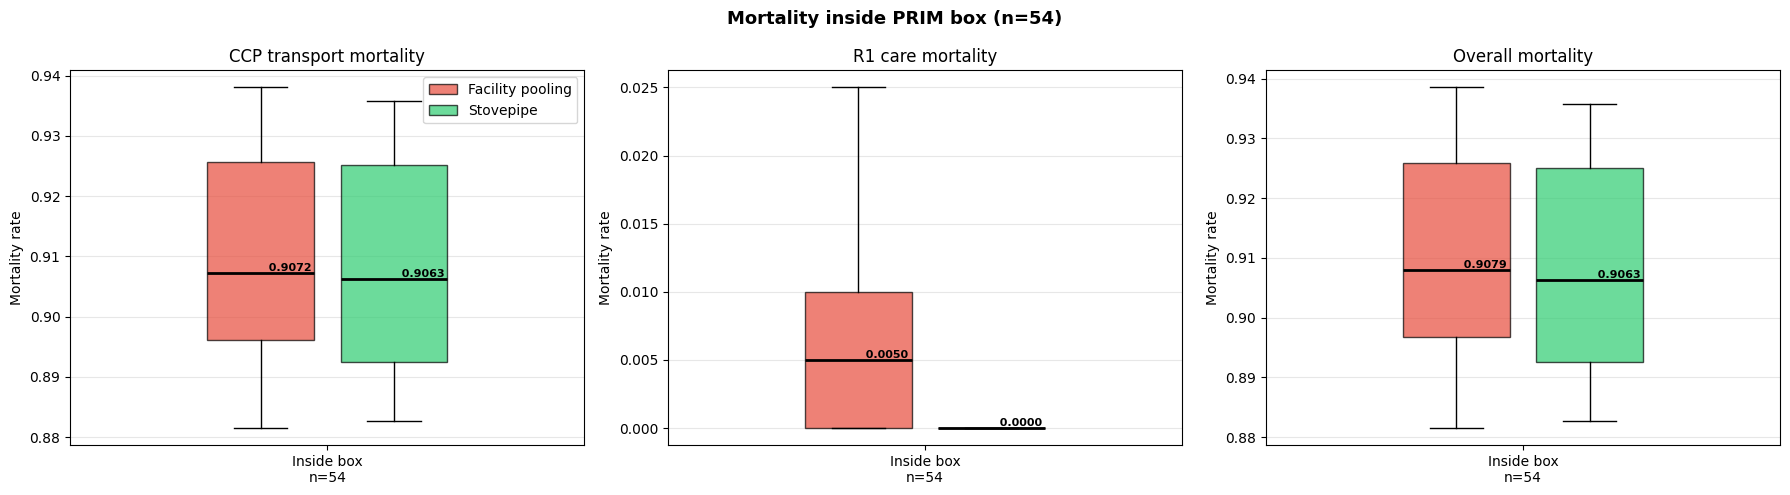

  mortality_ccp_transport_T1: Facility pooling=100.0%, Stovepipe=100.0%
  mortality_r1_care_T1: Facility pooling=66.7%, Stovepipe=0.0%

Median mortality with 95% CI inside PRIM box (n=54):
  mortality_ccp_transport_T1: Facility pooling median=0.9072 CI=[0.9022, 0.9146]
  mortality_ccp_transport_T1: Stovepipe median=0.9063 CI=[0.9019, 0.9106]
  mortality_r1_care_T1: Facility pooling median=0.0050 CI=[0.0033, 0.0092]
  mortality_r1_care_T1: Stovepipe median=0.0000 (constant)
  death_rate_T1_BCAS: Facility pooling median=0.9079 CI=[0.9032, 0.9163]
  death_rate_T1_BCAS: Stovepipe median=0.9063 CI=[0.9019, 0.9106]


In [17]:
_idx = box3.yi
_l1, _l2 = "Facility pooling", "Stovepipe"
_df1, _df2 = policy, stove

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
_c1, _c2 = "#e74c3c", "#2ecc71"
_w = 0.35

for _ai, (_col, _title) in enumerate([
    ("mortality_ccp_transport_T1", "CCP transport mortality"),
    ("mortality_r1_care_T1", "R1 care mortality"),
    ("death_rate_T1_BCAS", "Overall mortality"),
]):
    _d1 = _df1[_col].values[_idx]
    _d2 = _df2[_col].values[_idx]
    _bp1 = axes[_ai].boxplot([_d1], positions=[-_w/2], widths=_w*0.8, patch_artist=True,
                              showfliers=False, medianprops=dict(color="black", linewidth=2))
    _bp2 = axes[_ai].boxplot([_d2], positions=[_w/2], widths=_w*0.8, patch_artist=True,
                              showfliers=False, medianprops=dict(color="black", linewidth=2))
    _bp1["boxes"][0].set_facecolor(_c1); _bp1["boxes"][0].set_alpha(0.7)
    _bp2["boxes"][0].set_facecolor(_c2); _bp2["boxes"][0].set_alpha(0.7)
    axes[_ai].set_xticks([0])
    axes[_ai].set_xticklabels([f"Inside box\nn={len(_idx)}"])
    axes[_ai].set_title(_title)
    axes[_ai].set_ylabel("Mortality rate")
    axes[_ai].grid(True, alpha=0.3, axis="y")
    for _bp, _xp in [(_bp1, -_w/2), (_bp2, _w/2)]:
        _med = _bp["medians"][0].get_ydata()[0]
        axes[_ai].text(_xp, _med, f"  {_med:.4f}", ha="left", fontsize=8, fontweight="bold", va="bottom")

axes[0].legend([_bp1["boxes"][0], _bp2["boxes"][0]], [_l1, _l2], loc="upper right")
plt.suptitle(f"Mortality inside PRIM box (n={len(_idx)})", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

for _col in ["mortality_ccp_transport_T1", "mortality_r1_care_T1"]:
    _f1 = (_df1[_col].values[_idx] > 0).mean()
    _f2 = (_df2[_col].values[_idx] > 0).mean()
    print(f"  {_col}: {_l1}={_f1:.1%}, {_l2}={_f2:.1%}")

from scipy.stats import bootstrap as _bootstrap
print(f"\nMedian mortality with 95% CI inside PRIM box (n={len(_idx)}):")
for _col in ["mortality_ccp_transport_T1", "mortality_r1_care_T1", "death_rate_T1_BCAS"]:
    _vals = _df1[_col].values[_idx]
    if len(set(_vals)) > 1:
        _ci = _bootstrap((_vals,), np.median, confidence_level=0.95, n_resamples=9999, method='percentile').confidence_interval
        print(f"  {_col}: {_l1} median={np.median(_vals):.4f} CI=[{_ci.low:.4f}, {_ci.high:.4f}]")
    else:
        print(f"  {_col}: {_l1} median={np.median(_vals):.4f} (constant)")
    _vals2 = _df2[_col].values[_idx]
    if len(set(_vals2)) > 1:
        _ci2 = _bootstrap((_vals2,), np.median, confidence_level=0.95, n_resamples=9999, method='percentile').confidence_interval
        print(f"  {_col}: {_l2} median={np.median(_vals2):.4f} CI=[{_ci2.low:.4f}, {_ci2.high:.4f}]")
    else:
        print(f"  {_col}: {_l2} median={np.median(_vals2):.4f} (constant)")


## Summary: delta across PRIM boxes (helps / indifferent / hurts)


C:\Users\User\AppData\Local\Temp\ipykernel_18400\332374136.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([_d1, _d2, _d3], labels=["Helps (box1)", "Indifferent (box2)", "Hurts (box3)"],


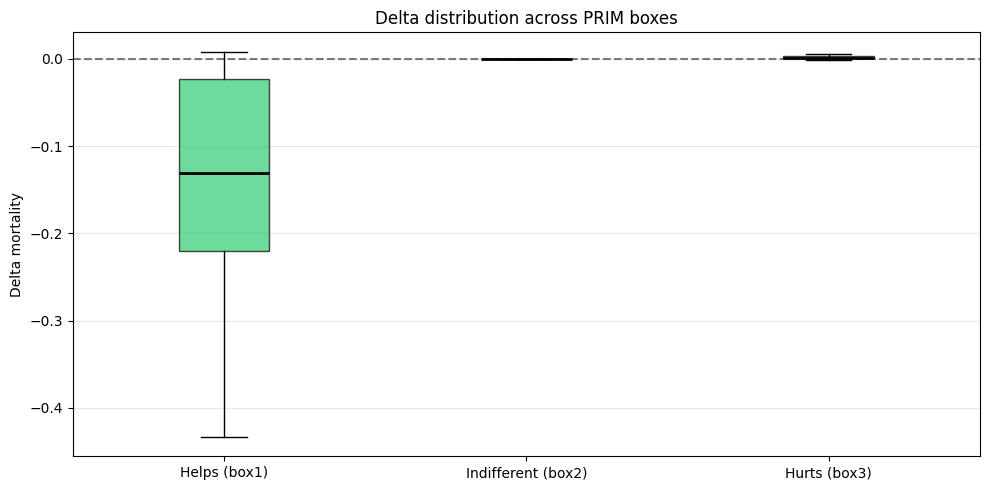

Helps        n=   54, helps=83.3%, hurts=14.8%, median=-0.1307, 95% CI [-0.1668, -0.0811]
Indifferent  n=   60, helps= 0.0%, hurts= 1.7%, median=+0.0000, 95% CI [+0.0000, +0.0000]
Hurts        n=   54, helps=13.0%, hurts=87.0%, median=+0.0014, 95% CI [+0.0012, +0.0023]


In [18]:
from scipy.stats import bootstrap as _bootstrap

_d1 = delta[box1.yi]
_d2 = delta[box2.yi]
_d3 = delta[box3.yi]

fig, ax = plt.subplots(figsize=(10, 5))
bp = ax.boxplot([_d1, _d2, _d3], labels=["Helps (box1)", "Indifferent (box2)", "Hurts (box3)"],
                patch_artist=True, showfliers=False, medianprops=dict(color="black", linewidth=2))
colors = ["#2ecc71", "#f39c12", "#e74c3c"]
for b, c in zip(bp["boxes"], colors):
    b.set_facecolor(c); b.set_alpha(0.7)
ax.axhline(0, color="black", linestyle="--", alpha=0.5)
ax.set_ylabel("Delta mortality")
ax.grid(True, alpha=0.3, axis="y")
plt.title("Delta distribution across PRIM boxes")
plt.tight_layout()
plt.show()

for bname, _d in [("Helps", _d1), ("Indifferent", _d2), ("Hurts", _d3)]:
    if len(set(_d)) > 1:
        _ci = _bootstrap((_d,), np.median, confidence_level=0.95, n_resamples=9999, method='percentile').confidence_interval
        print(f"{bname:<12} n={len(_d):>5}, helps={(_d<0).mean():>5.1%}, hurts={(_d>0).mean():>5.1%}, median={np.median(_d):+.4f}, 95% CI [{_ci.low:+.4f}, {_ci.high:+.4f}]")
    else:
        print(f"{bname:<12} n={len(_d):>5}, helps={(_d<0).mean():>5.1%}, hurts={(_d>0).mean():>5.1%}, median={np.median(_d):+.4f}")
